<a id="chapter-02"></a>

# Chapter 02 · OpenAI Gym API and Gymnasium / 环境接口

[← 学习索引](../README.md) · [项目主页](../../README.md) · [跳到本章扩展](#extension)

> 学习方式：按顺序读到代码单元，先预测输出再运行。正文只保留理解主线；非必要的证明、变体与工程细节放在[扩展](#extension)。

**学完本章，你应该能：**

- 理解 Gymnasium 的 space、reset、step
- 正确处理 terminated 与 truncated
- 用 wrapper 改造环境而不改环境源码

**开始前最好已经会：**

- 理解第 1 章的 agent/environment 交互
- 会写 `for` 循环
- 知道 tuple 解包


## 原书覆盖地图

| 原书主题 | 本 notebook 对应位置 | 深度 |
|---|---|---|
| The anatomy of the agent | 交互契约与算法流程 | 详细 |
| Hardware and software requirements | 索引的环境说明 | 实用 |
| Gymnasium spaces / environment / creation / CartPole | 符号表、代码实验 | 详细 |
| The random CartPole agent | 第一段可运行实验 | 完整小例子 |
| Wrappers / rendering / extra API | 源码路线、常见坑、扩展 | 详细 |

“详细”表示正文包含推导或完整数据流；“源码路线”表示正文解释职责并链接真实实现；次要变体保留在扩展区。这样可以明确看到本章没有把原书哪个主题悄悄跳过。


## 0. 先想一个问题

算法怎样在不关心游戏内部实现的情况下，同时操作 CartPole、Atari 和机器人？答案是一份严格的交互契约。

> 不必立刻回答。读完本章后再回到这里，尝试用两三句话作答。


## 1. 心智模型：先知道信息怎样流动

`reset()` 给出初始观测；`step(action)` 返回 `(obs, reward, terminated, truncated, info)`。一个 episode 在 `terminated or truncated` 时结束，但二者对 bootstrap 的含义不同。

学习时始终追问三件事：**当前已知什么？要估计什么？哪个量会被更新？** 这比先背算法名称更重要。


## 2. 符号表：先统一语言

| 符号/名称 | 含义 | 阅读时怎么想 |
|---|---|---|
| `observation` | 策略能看到的信息 | 不一定等于完整状态 |
| `action_space` | 合法动作集合 | 也负责随机采样 |
| `terminated` | MDP 自然终止 | 例如失败、成功 |
| `truncated` | 外部截断 | 例如时间上限 |
| `info` | 调试/评估附加信息 | 通常不直接输入策略 |

第一次阅读只需认识这些符号；看到公式时再回来查，不要求一次背完。


## 3. 分步推导：公式不是凭空出现的


### 1. 一次交互对应 MDP 的哪一部分

给定 $S_t=s,A_t=a$，环境按照转移分布产生下一状态和奖励：

$$S_{t+1},R_{t+1}\sim P(\cdot,\cdot\mid s,a)$$

Gymnasium 把这一步实现为：

```python
next_obs, reward, terminated, truncated, info = env.step(action)
```

### 2. 为什么要区分 terminated 和 truncated

TD 目标需要判断下一状态是否还有未来价值：

$$y_t=R_{t+1}+\gamma m_tV(S_{t+1})$$

自然终止时 $m_t=0$；时间限制截断不一定意味着状态没有未来，所以常取

$$m_t=1-\mathbb 1[\text{terminated}]$$

但 episode 控制流必须在 `terminated or truncated` 时 reset。这说明“停止采样”和“是否 bootstrap”是两个不同问题。

### 3. Wrapper 为什么是组合而不是复制环境

Wrapper 保持相同的 `reset/step` 接口，只变换 observation、action 或 reward，因此可一层层组合。顺序不同会得到不同 MDP，例如“先裁剪奖励再累计”和“先累计再裁剪”并不等价。


## 4. 手算一个最小例子


假设最后一步奖励为 1，$\gamma=0.9$，critic 认为下一状态价值为 5：

- 真正终止：$y=1+0.9\times0\times5=1$
- 仅时间截断：$y=1+0.9\times1\times5=5.5$

把 truncated 错当 terminated，会系统性低估时间上限附近的价值。


> 手算的目的不是练算术，而是给公式建立可检查的直觉。代码输出与手算矛盾时，先停下来找原因。


## 5. 本章公式卡


### 交互循环与终止语义

策略采样：$A_t\sim\pi(\cdot\mid S_t)$，环境采样：$S_{t+1}\sim P(\cdot\mid S_t,A_t)$。

- `terminated=True`：MDP 的真正终止状态，通常 bootstrap 值为 0。
- `truncated=True`：时间上限或外部条件截断；若下一状态仍有定义，训练目标通常仍应 bootstrap。

因此 TD mask 通常应是 $m_t=1-\mathbb 1[\text{terminated}]$，而不是简单使用 `done`。


这张卡用于复习，不替代上一节的推导。


## 6. 公式 ↔ 代码逐项对照

| 数学对象/步骤 | 代码对应 | 作用与形状提示 |
|---|---|---|
| $S_t$ | `obs` | 当前观测 |
| $A_t$ | `action` | 传给 `env.step` 的动作 |
| $R_{t+1}$ | `reward` | 动作之后获得 |
| $S_{t+1}$ | 新的 `obs` | 下一轮策略输入 |
| episode 结束 | `terminated or truncated` | 控制流 reset 条件 |
| bootstrap mask | `not terminated` | 价值目标中的 mask |

**从公式过渡到代码时：**下面的循环限制最多 200 步，即使环境版本或随机策略发生变化也会快速结束。关闭环境是 notebook 中容易漏掉的小细节。


## 7. 动手实验

运行前先做三件事：

1. 根据手算例子预测关键输出的方向或数量级；
2. 找到上一张表中的每个代码变量；
3. 运行后只改一个变量，观察结果是否符合公式。


In [1]:
try:
    import gymnasium as gym
except ImportError:
    gym = None

if gym is None:
    print("未安装 gymnasium；按项目 requirements.txt 安装后再运行本单元。")
else:
    env = gym.make("CartPole-v1")
    obs, info = env.reset(seed=42)
    total_reward = 0.0
    for step in range(200):
        action = env.action_space.sample()  # 随机策略只是接口演示
        obs, reward, terminated, truncated, info = env.step(action)
        total_reward += reward
        if terminated or truncated:
            break
    env.close()
    print({"steps": step + 1, "return": total_reward, "last_obs_shape": obs.shape})


{'steps': 19, 'return': 19.0, 'last_obs_shape': (4,)}


### 怎样读运行结果

随机策略的 return 每次可能不同，这是环境与动作采样共同造成的。重点不是分数，而是确认 observation shape、返回值顺序和结束条件。

如果结果不符合描述，先检查随机种子、终止 mask、数组 shape 和依赖版本，而不是马上调超参数。


## 8. 完整算法：把前面的零件装起来


```text
obs, info = env.reset(seed=seed)
while True:
    action = policy(obs)
    next_obs, reward, terminated, truncated, info = env.step(action)
    store(obs, action, reward, terminated, next_obs)
    obs = next_obs
    if terminated or truncated:
break
env.close()
```

存储 transition 时建议保留 `terminated` 与 `truncated`，不要过早合成一个 `done`。控制流用二者的 OR；bootstrap mask 通常只看 `terminated`。


## 9. 第二个验证实验

第一个实验负责建立直觉；下面这个实验专门验证一个容易写错的性质。它仍然保持轻量，目的是让你能用断言判断实现是否符合公式。


In [2]:
# 同一 next_value，在自然终止与时间截断下产生不同 TD target。
reward, gamma, next_value = 1.0, 0.9, 5.0
cases = [(True, False), (False, True), (False, False)]
for terminated, truncated in cases:
    target = reward + gamma * (not terminated) * next_value
    stop_episode = terminated or truncated
    print({"terminated": terminated, "truncated": truncated,
           "stop": stop_episode, "target": target})


{'terminated': True, 'truncated': False, 'stop': True, 'target': 1.0}
{'terminated': False, 'truncated': True, 'stop': True, 'target': 5.5}
{'terminated': False, 'truncated': False, 'stop': False, 'target': 5.5}


## 10. 项目源码精读路线

| 文件 | 重点类/函数 | 阅读目的 |
|---|---|---|
| [`01_agent_anatomy.py`](../../Chapter02/01_agent_anatomy.py) | `Environment`, `Agent.step` | 先看自制最小接口，理解控制权在哪一侧 |
| [`02_cartpole_random.py`](../../Chapter02/02_cartpole_random.py) | 主循环 | 对应 notebook 的 reset/step 生命周期 |
| [`03_random_action_wrapper.py`](../../Chapter02/03_random_action_wrapper.py) | `RandomActionWrapper.action` | 理解 ActionWrapper 只变换动作 |
| [`04_cartpole_random_monitor.py`](../../Chapter02/04_cartpole_random_monitor.py) | 视频/监控 | 理解评估记录与训练循环分离 |

<details>
<summary>为什么按这个顺序读</summary>

源码阅读顺序应从 `01_agent_anatomy.py` 开始，因为它把 Gymnasium 隐藏的协议显式写出；再看随机 agent；最后看 wrapper。`RandomActionWrapper` 的 `action()` 在底层环境收到动作前拦截它，因此 epsilon 随机性属于环境包装层，而不是策略网络。

</details>

notebook 的实验负责隔离原理，仓库脚本负责完整环境、日志和训练。阅读时拿着第 6 节对照表寻找同一数学对象；变量名可以不同，数据语义不能不同。


## 11. 训练曲线、调参与失败复盘

**本章主诊断指标：**简化平衡环境中的最佳 episode length

下面的曲线来自可重复运行的微型训练，不是手工填写的数据。它用于学习“该看什么、怎样判断”；原书规模的训练应使用上一节链接的项目脚本，并同时保存配置、随机种子、环境步数和 wall-clock。

> 曲线阅读顺序：先看任务指标，再看优化指标，最后看资源指标。单次最好成绩不能代替多随机种子均值与波动。


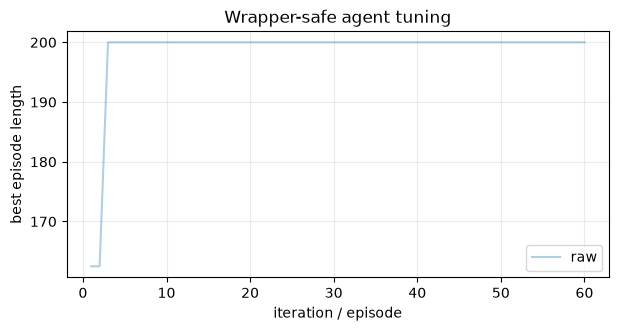

best gain: [1.45  0.286] score: 200.0


In [3]:
import numpy as np
import matplotlib.pyplot as plt

def plot_curve(series, title, ylabel, *, window=1):
    # Plot raw measurements and an optional moving average.
    values = np.asarray(series, dtype=float)
    x = np.arange(1, len(values) + 1)
    plt.figure(figsize=(7, 3.2))
    plt.plot(x, values, alpha=0.35, label="raw")
    if window > 1 and len(values) >= window:
        smooth = np.convolve(values, np.ones(window) / window, mode="valid")
        plt.plot(x[window - 1:], smooth, linewidth=2, label=f"MA({window})")
    plt.title(title)
    plt.xlabel("iteration / episode")
    plt.ylabel(ylabel)
    plt.grid(alpha=0.25)
    plt.legend()
    plt.show()
    plt.close()


rng = np.random.default_rng(2)

def evaluate(gain, episodes=20):
    scores = []
    for start in np.linspace(-0.18, 0.18, episodes):
        angle, velocity = start, 0.0
        for step in range(200):
            action = -np.sign(gain[0] * angle + gain[1] * velocity)
            velocity += 0.025 * action + 0.01 * angle
            angle += velocity
            if abs(angle) > 0.5:
                break
        scores.append(step + 1)
    return np.mean(scores)

gain = np.array([1.0, 0.0])
best = evaluate(gain)
history = []
for iteration in range(60):
    candidate = gain + rng.normal(0, 0.25, size=2)
    score = evaluate(candidate)
    if score > best:
        gain, best = candidate, score
    history.append(best)

plot_curve(history, "Wrapper-safe agent tuning", "best episode length")
print("best gain:", np.round(gain, 3), "score:", best)


### 曲线怎么读

阶梯状上升是正常的：随机搜索只有找到更好的控制参数才更新 best。若曲线始终不动，先检查 `reset/step`、终止条件和动作语义，而不是增加网络。

### 调参过程：一次只改变一个因素

- 先让随机 agent 跑通，记录 episode length 基线。
- 固定初始状态集合，再调控制增益，避免评估噪声掩盖变化。
- 最后换多组初始状态验证，防止只记住单一 reset。

### 失败案例复盘

- 把 `terminated` 和 `truncated` 都忽略，episode 永不结束。
- wrapper 改了 observation，却忘记同步 `observation_space`。
- 用同一随机 episode 既调参又报告成绩，产生选择偏差。

遇到失败时先保存配置和原始曲线，复现后再修；不要一边改环境、一边改网络、一边改学习率，否则无法知道修复来自哪里。


## 12. 实用技巧与常见坑

- 固定 `reset(seed=...)` 只是复现实验的一部分，还要固定 NumPy/PyTorch 随机种子。
- 训练时不要开实时渲染，它常常成为主要性能瓶颈。
- wrapper 的顺序会改变语义，尤其是奖励裁剪、帧堆叠与时间限制。

这些不是附属知识：RL 结果方差大，很多“算法没学会”其实是终止语义、shape、数据泄漏或评估方式错误。


## 13. 动手练习

写一个 `RewardWrapper` 把每步奖励乘 0.1，并检查 episode 长度是否保持不变。

<details>
<summary>完成标准（做完再展开）</summary>

不只给出结果；还应说明改了哪个变量、对应哪条公式、变化是否符合预期，并写出至少一个边界情况。若能用 `assert` 固化结论更好。
</details>


## 14. 练习参考答案

<details>
<summary>完成练习后再展开</summary>

继承 `gym.RewardWrapper` 并实现 `reward(self, reward): return 0.1 * reward`。用相同 seed 分别运行原环境和包装环境；episode 步数应一致，总回报应缩小到约十分之一。若步数变化，说明 wrapper 意外改了动作、观测或终止条件。

</details>


## 15. 合上 notebook 后，脑中应留下什么

- `reset` 和 `step` 是环境的最小契约。
- episode 结束条件与 bootstrap mask 不能混为一谈。
- 训练时关闭渲染，评估时再录制。
- Wrapper 的组合顺序是算法定义的一部分。

回到开头的那个问题。现在请不用公式，向一个没学过本章的人解释答案；能讲清楚，才算真正理解。


## 16. 两分钟自测

**问题：**`truncated=True, terminated=False` 时，循环是否停止？TD target 是否一定把下一状态价值置零？

<details>
<summary>展开答案</summary>

循环应停止并 reset；但 TD target 通常仍 bootstrap，因为截断不等于 MDP 自然终止。具体仍要结合环境定义。
</details>


## 17. 与前后章节连接

第 3 章学习用 PyTorch 表示可训练策略；第 4 章第一次把 Gym trajectory 变成监督训练数据。

学习强化学习最怕把算法记成孤岛。每章结束时，都应能说明本章复用了前面的什么，又为后面准备了什么。


<a id="extension"></a>

## 扩展：主线学完后再深挖

向量环境把多个环境的观测拼成 batch；录制视频需要 `render_mode='rgb_array'` 并使用 `RecordVideo`。

扩展内容用于建立知识地图，不要求第一次学习就掌握。先确保能完成上面的两分钟自测，再决定是否继续。

[↑ 回到开头](#chapter-02) · [← 学习索引](../README.md)
